# CHB24 + CHB12 Time-to-Seizure Forecasting via a State Deviation Index + TCN

**Objective.** The 14 standardized qEEG features of each 30-second epoch are
collapsed into a single scalar -- the **EEG State Deviation Index** -- that
measures how far an epoch's EEG state lies from a stable, TRAIN-only
interictal baseline. The resulting index trajectory is tracked over time and
used to train the same causal TCN architecture used elsewhere in this
project to forecast time-to-next-seizure.

```text
14 qEEG features
  -> standardized (zero mean / unit variance, fit on a TRAIN STABLE BASELINE only)
  -> distance from that baseline (PCA-whitened Euclidean / Mahalanobis-equivalent)
  -> ONE scalar eeg_state_index per epoch (>= 0, 0 = exactly at baseline)
  -> chronological trajectory of that index
  -> TCN reads 10 consecutive index values (5 minutes)
  -> TCN detects temporal patterns in how the index is moving
  -> 4-class distribution over time-to-next-seizure
  -> cumulative 30/60/120-second transition-risk curve
```

**Combined-subject dataset.** This notebook combines CHB24 with CHB12, a
second seizure-dense CHB-MIT subject preprocessed by
`EEG_CHB12_preprocessing.ipynb` using an identical filtering / epoching /
feature / schema pipeline. Of CHB12's montage-compatible seizure-containing
recordings, the subset actually processed by that notebook (5 recordings, 19
seizure events) is used here; recordings identified there as
montage-incompatible are excluded for that reason, and the remaining
montage-compatible recordings not yet processed are simply absent from this
combined table. Because the training population differs from any earlier
CHB24-only run, the feature scaler, the PCA-whitening transform, and the TCN
are all fit from scratch on the combined data.

**Design choice.** The index measures each epoch's distance from a stable
TRAIN interictal baseline centroid -- how far that epoch's EEG state sits
from what this training population's normal EEG looks like -- rather than a
direction of maximum overall variance. A genuine drift away from normal EEG
is intended to show up directly as a rising index value, which is the
pre-seizure precursor pattern this experiment is designed to detect.

**Combining two subjects.** CHB24 and CHB12 are both CHB-MIT subjects
acquired under the same protocol, sampling rate, and (after CHB12's montage
reconciliation) channel montage, so this is a cross-subject combination
within a single dataset, not a cross-dataset mixing of REST/SLEEP/CHB, which
the project's working contract prohibits without explicit justification.
Fitting one shared baseline and scaler across both subjects' interictal
epochs means the "stable EEG" reference is a two-subject average rather than
either subject's own individual baseline; this is a real methodological
simplification, reported explicitly here and revisited in the closing
summary.

This notebook does not modify `EEG_preprocessing.ipynb`,
`EEG_CHB24_preprocessing.ipynb`, or `EEG_CHB12_preprocessing.ipynb`.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

repo_root = Path("/home/evgenija/projects/EEG_timeseries_project")
chb24_features_path = repo_root / "outputs" / "features_chb24_forecasting.parquet"
chb12_features_path = repo_root / "outputs" / "features_chb12_forecasting.parquet"

for p, notebook in [(chb24_features_path, "EEG_CHB24_preprocessing.ipynb"),
                    (chb12_features_path, "EEG_CHB12_preprocessing.ipynb")]:
    if not p.exists():
        raise FileNotFoundError(f"{p} not found. Run {notebook} first.")

df_chb24 = pd.read_parquet(chb24_features_path)
df_chb12 = pd.read_parquet(chb12_features_path)

FEATURE_COLS = [
    "std", "var", "rms", "delta", "theta", "alpha", "beta",
    "rel_delta", "rel_theta", "rel_alpha", "rel_beta",
    "theta_alpha_ratio", "delta_beta_ratio", "entropy",
]
for name, part in [("CHB24", df_chb24), ("CHB12", df_chb12)]:
    missing_features = [c for c in FEATURE_COLS if c not in part.columns]
    if missing_features:
        raise ValueError(f"{name}: expected qEEG feature columns missing: {missing_features}")

# Schema must match exactly before concatenation -- both notebooks were
# built to produce an identical column set; verify rather than assume.
cols_chb24, cols_chb12 = set(df_chb24.columns), set(df_chb12.columns)
if cols_chb24 != cols_chb12:
    raise ValueError(
        f"CHB24/CHB12 schema mismatch: only_in_chb24={sorted(cols_chb24 - cols_chb12)}, "
        f"only_in_chb12={sorted(cols_chb12 - cols_chb24)}"
    )

# recording_id is unique per subject by construction ("chb_s24_r.." vs
# "chb_s12_r.."), so a plain concat cannot collide two different recordings
# under the same id -- verified explicitly rather than assumed.
overlap = set(df_chb24["recording_id"]) & set(df_chb12["recording_id"])
if overlap:
    raise ValueError(f"recording_id collision between CHB24 and CHB12: {overlap}")

df = pd.concat([df_chb24, df_chb12], ignore_index=True)

model_out_dir = repo_root / "outputs" / "modeling" / "tcn_state_deviation_forecasting"
model_out_dir.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(model_out_dir / name, dpi=150, bbox_inches="tight")

print("=" * 60)
print("LOADED + COMBINED CHB24 + CHB12 FEATURE TABLES")
print("=" * 60)
print(f"CHB24: shape={df_chb24.shape}, recordings={sorted(df_chb24['recording_id'].unique())}")
print(f"CHB12: shape={df_chb12.shape}, recordings={sorted(df_chb12['recording_id'].unique())}")
print(f"\nCombined shape        : {df.shape}")
print(f"Combined recordings   : {sorted(df['recording_id'].unique())}")
print(f"n_recordings          : {df['recording_id'].nunique()}")
print(f"n_rows                : {len(df)}")
print(f"seizure-overlap epochs (y_seizure==1): {int((df['y_seizure'] == 1).sum())}")
print(f"  CHB24 seizure epochs: {int((df_chb24['y_seizure'] == 1).sum())}")
print(f"  CHB12 seizure epochs: {int((df_chb12['y_seizure'] == 1).sum())}")
print(f"[OK] all {len(FEATURE_COLS)} qEEG feature columns present")
print(f"Outputs will be saved to: {model_out_dir}")

LOADED + COMBINED CHB24 + CHB12 FEATURE TABLES
CHB24: shape=(1440, 24), recordings=['chb_s24_r01', 'chb_s24_r03', 'chb_s24_r04', 'chb_s24_r06', 'chb_s24_r07', 'chb_s24_r09', 'chb_s24_r11', 'chb_s24_r13', 'chb_s24_r14', 'chb_s24_r15', 'chb_s24_r17', 'chb_s24_r21']
CHB12: shape=(600, 24), recordings=['chb_s12_r06', 'chb_s12_r08', 'chb_s12_r23', 'chb_s12_r38', 'chb_s12_r42']

Combined shape        : (2040, 24)
Combined recordings   : ['chb_s12_r06', 'chb_s12_r08', 'chb_s12_r23', 'chb_s12_r38', 'chb_s12_r42', 'chb_s24_r01', 'chb_s24_r03', 'chb_s24_r04', 'chb_s24_r06', 'chb_s24_r07', 'chb_s24_r09', 'chb_s24_r11', 'chb_s24_r13', 'chb_s24_r14', 'chb_s24_r15', 'chb_s24_r17', 'chb_s24_r21']
n_recordings          : 17
n_rows                : 2040
seizure-overlap epochs (y_seizure==1): 69
  CHB24 seizure epochs: 28
  CHB12 seizure epochs: 41
[OK] all 14 qEEG feature columns present
Outputs will be saved to: /home/evgenija/projects/EEG_timeseries_project/outputs/modeling/tcn_state_deviation_foreca

### The 14 qEEG Feature Representation

Every 30-second epoch is summarized by 14 numbers -- quantitative EEG
("qEEG") features computed from the filtered, multi-channel signal. They
fall into four groups:

| group | features | what they capture |
|---|---|---|
| **Amplitude** | `std`, `var`, `rms` | Overall signal amplitude/energy in the epoch -- three closely related measures of "how big are the voltage swings", not frequency-specific. |
| **Absolute band power** | `delta` (0.5-4 Hz), `theta` (4-8 Hz), `alpha` (8-13 Hz), `beta` (13-30 Hz) | Welch-PSD power in each classical EEG frequency band -- how much signal energy falls in slow (delta), light-sleep/drowsy (theta), relaxed-wakeful (alpha), and active/alert (beta) rhythms. Seizure activity typically produces large, abnormal shifts in these bands. |
| **Relative band power** | `rel_delta`, `rel_theta`, `rel_alpha`, `rel_beta` | Each band's power as a fraction of total band power (they sum to ~1) -- the epoch's frequency *composition*, independent of overall amplitude. |
| **Cross-band ratios & complexity** | `theta_alpha_ratio`, `delta_beta_ratio`, `entropy` | Two band-power ratios often used as slowing indicators in clinical qEEG, plus Shannon entropy of the normalized power spectrum (low entropy = energy concentrated in a few frequencies -- often true during a seizure; high entropy = broadband, "noise-like" spectrum -- more typical of normal waking EEG). |

All 14 are computed identically for every epoch, in every recording, in
both CHB24 and CHB12 (see `EEG_CHB24_preprocessing.ipynb` /
`EEG_CHB12_preprocessing.ipynb` for the exact extraction code), so they are
directly comparable across recordings and subjects. Every downstream step in
this notebook (the baseline, the index, the TCN) operates on this same
14-number-per-epoch representation rather than the raw EEG signal directly.


### Combined Feature Table Loading

The verified CHB24 and CHB12 per-epoch qEEG feature tables are loaded and
concatenated after confirming their column schemas are identical and that
recording identifiers do not collide between subjects. Each row represents
one 30-second epoch with its 14 qEEG features and recording/time/seizure
metadata; no transformation has been applied to this raw material at this
point. Output paths and a figure-saving helper are set up so that each
figure produced below is written to disk immediately after being plotted.


In [2]:
print("=" * 60)
print("CONSTRUCTING THE FORECASTING TARGET: forecast_class")
print("=" * 60)

# An epoch where a seizure is CURRENTLY happening (y_seizure == 1) cannot be
# asked "how soon is the next seizure" -- it is excluded from having a
# forecast_class entirely (not given a fabricated label).
eligible_mask = df["y_seizure"] == 0
n_excluded = int((~eligible_mask).sum())
print(f"Excluding {n_excluded} seizure-overlapping epochs (y_seizure==1) from "
      f"the label (they remain in `df` and can still be used as historical "
      f"context inside a sequence window later).")

dt = df["time_to_next_seizure_sec"]

# Boundary note: dt == 0 happens when an epoch's END lands exactly on a
# seizure's onset second. That is "imminent" (the very next instant is
# onset), so class 0 uses an INCLUSIVE lower bound (0 <= dt <= 30).
conditions = [
    (dt >= 0) & (dt <= 30),
    (dt > 30) & (dt <= 60),
    (dt > 60) & (dt <= 120),
]
choices = [0, 1, 2]
df["forecast_class"] = np.select(conditions, choices, default=3)
df.loc[~eligible_mask, "forecast_class"] = -1  # sentinel: "not a valid target"

CLASS_NAMES = {0: "0-30s", 1: "30-60s", 2: "60-120s", 3: ">120s"}
CLASS_ORDER = [0, 1, 2, 3]

model_df = df[eligible_mask].copy()
class_counts = model_df["forecast_class"].value_counts().sort_index().reindex(CLASS_ORDER, fill_value=0)
print("\nforecast_class distribution (eligible epochs only):")
for c in CLASS_ORDER:
    print(f"  class {c} ({CLASS_NAMES[c]:>7s}): {int(class_counts[c]):5d}")

CONSTRUCTING THE FORECASTING TARGET: forecast_class
Excluding 69 seizure-overlapping epochs (y_seizure==1) from the label (they remain in `df` and can still be used as historical context inside a sequence window later).

forecast_class distribution (eligible epochs only):
  class 0 (  0-30s):    38
  class 1 ( 30-60s):    34
  class 2 (60-120s):    62
  class 3 (  >120s):  1837


### Forecasting Target Construction

The same target definition used throughout this project:

| class | meaning |
|---|---|
| 0 | next seizure starts within 0-30s |
| 1 | next seizure starts within 30-60s |
| 2 | next seizure starts within 60-120s |
| 3 | no seizure expected within the next 120s |

`forecast_class = -1` is a sentinel meaning the epoch is not a valid
forecasting target (it is itself seizure-overlapping). `forecast_class == 3`
is reused below as one of the conditions defining a stable baseline epoch,
so both concepts share a single threshold definition.


In [3]:
print("=" * 60)
print("RECORDING-LEVEL TRAIN / VALIDATION / TEST SPLIT (CHB24 + CHB12)")
print("=" * 60)

per_recording_counts = (
    model_df.groupby(["recording_id", "forecast_class"]).size().unstack(fill_value=0)
)
per_recording_counts = per_recording_counts.reindex(columns=CLASS_ORDER, fill_value=0)
print("\nPer-recording forecast_class counts (inspected before choosing the split):")
print(per_recording_counts)

# Deliberately chosen (not randomly), after inspecting the table above:
# CHB24's existing TRAIN/VAL/TEST recordings are kept unchanged; CHB12's 5
# available recordings (see EEG_CHB12_preprocessing.ipynb -- CHB12 expansion
# was time-limited to 5 of 10 montage-compatible seizure recordings tonight)
# are added so that VAL and TEST each receive one of CHB12's richer,
# imminent-class-dense recordings (chb_s12_r38, chb_s12_r42) -- giving the
# primary question this run exists to answer (do recall/F1 for the
# imminent-seizure classes become > 0 on HELD-OUT data?) real support to be
# answered on -- while most of CHB12 goes to TRAIN to maximize learning
# signal for the rare classes.
TRAIN_RECORDINGS = [
    "chb_s24_r04", "chb_s24_r07", "chb_s24_r09", "chb_s24_r11",
    "chb_s24_r13", "chb_s24_r14", "chb_s24_r15", "chb_s24_r17",
    "chb_s12_r06", "chb_s12_r08", "chb_s12_r23",
]
VAL_RECORDINGS = ["chb_s24_r03", "chb_s24_r06", "chb_s12_r38"]
TEST_RECORDINGS = ["chb_s24_r01", "chb_s24_r21", "chb_s12_r42"]

all_recordings = set(df["recording_id"].unique())
assigned = set(TRAIN_RECORDINGS) | set(VAL_RECORDINGS) | set(TEST_RECORDINGS)
if assigned != all_recordings:
    raise ValueError(f"Split does not cover all recordings exactly once: "
                      f"missing={all_recordings - assigned}, extra={assigned - all_recordings}")
if len(assigned) != len(TRAIN_RECORDINGS) + len(VAL_RECORDINGS) + len(TEST_RECORDINGS):
    raise ValueError("A recording appears in more than one split -- this would leak data.")

print(f"\nTRAIN recordings ({len(TRAIN_RECORDINGS)}): {TRAIN_RECORDINGS}")
print(f"VALIDATION recordings ({len(VAL_RECORDINGS)}): {VAL_RECORDINGS}")
print(f"TEST recordings ({len(TEST_RECORDINGS)}): {TEST_RECORDINGS}")

print("\nClass counts per split (eligible epochs):")
for split_name, recs in [("TRAIN", TRAIN_RECORDINGS), ("VALIDATION", VAL_RECORDINGS), ("TEST", TEST_RECORDINGS)]:
    counts = model_df[model_df["recording_id"].isin(recs)]["forecast_class"].value_counts()
    counts = counts.reindex(CLASS_ORDER, fill_value=0)
    n_chb24 = sum(1 for r in recs if r.startswith("chb_s24"))
    n_chb12 = sum(1 for r in recs if r.startswith("chb_s12"))
    print(f"  {split_name:10s} ({n_chb24} CHB24 + {n_chb12} CHB12 recordings): " +
          ", ".join(f"{CLASS_NAMES[c]}={int(counts[c])}" for c in CLASS_ORDER))

train_row_mask = df["recording_id"].isin(TRAIN_RECORDINGS).to_numpy()
val_row_mask = df["recording_id"].isin(VAL_RECORDINGS).to_numpy()
test_row_mask = df["recording_id"].isin(TEST_RECORDINGS).to_numpy()

RECORDING-LEVEL TRAIN / VALIDATION / TEST SPLIT (CHB24 + CHB12)

Per-recording forecast_class counts (inspected before choosing the split):


forecast_class  0  1   2    3
recording_id                 
chb_s12_r06     2  2   4  107
chb_s12_r08     4  4   8   99
chb_s12_r23     4  3   2  101
chb_s12_r38     5  5   8   90
chb_s12_r42     6  5  10   90
chb_s24_r01     3  2   4  108
chb_s24_r03     2  2   4  109
chb_s24_r04     3  3   6  104
chb_s24_r06     1  1   2  114
chb_s24_r07     1  0   0  118
chb_s24_r09     1  1   2  115
chb_s24_r11     1  1   2  113
chb_s24_r13     1  1   2  114
chb_s24_r14     1  1   2  114
chb_s24_r15     1  1   2  115
chb_s24_r17     1  1   2  113
chb_s24_r21     1  1   2  113

TRAIN recordings (11): ['chb_s24_r04', 'chb_s24_r07', 'chb_s24_r09', 'chb_s24_r11', 'chb_s24_r13', 'chb_s24_r14', 'chb_s24_r15', 'chb_s24_r17', 'chb_s12_r06', 'chb_s12_r08', 'chb_s12_r23']
VALIDATION recordings (3): ['chb_s24_r03', 'chb_s24_r06', 'chb_s12_r38']
TEST recordings (3): ['chb_s24_r01', 'chb_s24_r21', 'chb_s12_r42']

Class counts per split (eligible epochs):
  TRAIN      (8 CHB24 + 3 CHB12 recordings): 0-30s=20, 30

### Recording-Level Train / Validation / Test Split

Each recording, whether from CHB24 or CHB12, is assigned entirely to TRAIN,
VALIDATION, or TEST, following the recording-level leakage-avoidance rule
used throughout this project. CHB24's existing split is kept unchanged;
CHB12's available recordings are distributed across the three sets so that
VALIDATION and TEST each receive one CHB12 recording with substantial
imminent-class support (`chb_s12_r38`, `chb_s12_r42`), chosen from the
inspected per-recording class counts, rather than leaving VALIDATION/TEST
with only CHB24's comparatively sparse imminent-class counts.


In [4]:
print("=" * 60)
print("DEFINING THE STABLE TRAIN BASELINE")
print("=" * 60)

# A "stable interictal baseline" epoch must be:
#   (a) inside a TRAIN recording only -- the baseline must not depend on
#       anything the model is later validated or tested on,
#   (b) not itself seizure-overlapping (y_seizure == 0), and
#   (c) not within 120 seconds of the NEXT seizure -- i.e. forecast_class
#       == 3 (">120s"). This reuses the exact threshold already computed
#       for the label, instead of re-deriving a second "how close to a
#       seizure" rule.
y_seizure_np = df["y_seizure"].to_numpy()
forecast_class_np = df["forecast_class"].to_numpy()

baseline_mask = train_row_mask & (y_seizure_np == 0) & (forecast_class_np == 3)

n_train_total = int(train_row_mask.sum())
n_train_seizure = int((train_row_mask & (y_seizure_np == 1)).sum())
n_train_near_seizure = int((train_row_mask & (y_seizure_np == 0) & (forecast_class_np != 3)).sum())
n_baseline = int(baseline_mask.sum())

print(f"TRAIN recording epochs (all)                      : {n_train_total}")
print(f"  excluded -- seizure-overlapping (y_seizure==1)   : {n_train_seizure}")
print(f"  excluded -- within 120s of a seizure              : {n_train_near_seizure}")
print(f"  STABLE BASELINE epochs (used to fit scaler+index) : {n_baseline}")
print(f"  ({n_baseline} / {n_train_total} = {100*n_baseline/n_train_total:.1f}% of TRAIN epochs)")

MIN_BASELINE_PER_FEATURE = 10
if n_baseline < MIN_BASELINE_PER_FEATURE * len(FEATURE_COLS):
    raise ValueError(
        f"Only {n_baseline} baseline epochs for {len(FEATURE_COLS)} features "
        f"(< {MIN_BASELINE_PER_FEATURE}x rule of thumb) -- too few to define "
        f"a stable reference distribution."
    )
print(f"\n[OK] {n_baseline} baseline epochs >= {MIN_BASELINE_PER_FEATURE} x "
      f"{len(FEATURE_COLS)} features -- enough to estimate a covariance structure.")

DEFINING THE STABLE TRAIN BASELINE
TRAIN recording epochs (all)                      : 1320
  excluded -- seizure-overlapping (y_seizure==1)   : 37
  excluded -- within 120s of a seizure              : 70
  STABLE BASELINE epochs (used to fit scaler+index) : 1213
  (1213 / 1320 = 91.9% of TRAIN epochs)

[OK] 1213 baseline epochs >= 10 x 14 features -- enough to estimate a covariance structure.


### Stable Interictal Baseline Definition

The reference against which the state deviation index is measured is
defined as TRAIN-recording epochs that are neither seizure-overlapping nor
within 120 seconds of an upcoming seizure. Only these epochs are used to fit
the feature scaler and the distance transform below; validation and test
recordings never contribute, and seizure-adjacent TRAIN epochs are also
excluded, since the index is intended to measure deviation from a genuinely
stable reference rather than from the TRAIN population's average, which
would already be pulled toward seizure and near-seizure activity.


In [5]:
print("=" * 60)
print("STANDARDIZE THE 14 qEEG FEATURES (fit on the TRAIN STABLE BASELINE only)")
print("=" * 60)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(df.loc[baseline_mask, FEATURE_COLS])

standardized_all = scaler.transform(df[FEATURE_COLS])  # (n_rows, 14), every epoch, incl. seizure ones

print(f"Scaler fit on {n_baseline} STABLE BASELINE epochs only "
      f"(TRAIN, non-seizure, forecast_class == '>120s').")
print(f"\nPer-feature baseline mean:\n{pd.Series(scaler.mean_, index=FEATURE_COLS).round(4)}")
print(f"\nPer-feature baseline std:\n{pd.Series(np.sqrt(scaler.var_), index=FEATURE_COLS).round(4)}")

STANDARDIZE THE 14 qEEG FEATURES (fit on the TRAIN STABLE BASELINE only)


Scaler fit on 1213 STABLE BASELINE epochs only (TRAIN, non-seizure, forecast_class == '>120s').

Per-feature baseline mean:
std                   0.0000
var                   0.0000
rms                   0.0000
delta                 0.0000
theta                 0.0000
alpha                 0.0000
beta                  0.0000
rel_delta             0.7479
rel_theta             0.1508
rel_alpha             0.0359
rel_beta              0.0645
theta_alpha_ratio     4.9794
delta_beta_ratio     32.8260
entropy               0.6367
dtype: float64

Per-feature baseline std:
std                   0.0000
var                   0.0000
rms                   0.0000
delta                 0.0000
theta                 0.0000
alpha                 0.0000
beta                  0.0000
rel_delta             0.1036
rel_theta             0.0685
rel_alpha             0.0218
rel_beta              0.0766
theta_alpha_ratio     2.4232
delta_beta_ratio     36.7678
entropy               0.0851
dtype: float64


### Feature Standardization on the Stable Baseline

The 14 qEEG features are standardized as `x_scaled = (x - baseline_mean) /
baseline_std`, with `baseline_mean` and `baseline_std` computed only from
the TRAIN stable-baseline epochs defined above, across both CHB24 and
CHB12, rather than from all TRAIN epochs -- so that "normal" is not pulled
toward seizure-like values. This baseline is fit from scratch on the
combined two-subject population; the resulting "stable EEG" reference is
therefore a two-subject average rather than either subject's own individual
baseline, a methodological simplification reported here and revisited in
the closing summary. After fitting, the identical transform is applied to
every epoch in `df` -- TRAIN, VALIDATION, TEST, and seizure-overlapping
epochs from both subjects alike -- so no baseline-fitting information leaks
into the transformed features used downstream.


In [6]:
print("=" * 60)
print("COVARIANCE DIAGNOSTICS ON THE STANDARDIZED BASELINE")
print("=" * 60)

Xb = standardized_all[baseline_mask]  # (n_baseline, 14) standardized baseline features

cov_baseline = np.cov(Xb, rowvar=False)
eigvals_cov = np.linalg.eigvalsh(cov_baseline)[::-1]  # descending
rank_cov = int(np.linalg.matrix_rank(cov_baseline, tol=1e-8))
condition_number = float(eigvals_cov[0] / max(eigvals_cov[-1], 1e-300))

print(f"Baseline covariance matrix shape : {cov_baseline.shape}")
print(f"Eigenvalues (largest -> smallest):\n{np.round(eigvals_cov, 6)}")
print(f"Numerical rank (tol=1e-8)        : {rank_cov} / {len(FEATURE_COLS)}")
print(f"Condition number (max/min eigval): {condition_number:.3e}")

corr_baseline = pd.DataFrame(Xb, columns=FEATURE_COLS).corr()
highly_correlated = []
for i in range(len(FEATURE_COLS)):
    for j in range(i + 1, len(FEATURE_COLS)):
        r = corr_baseline.iloc[i, j]
        if abs(r) > 0.95:
            highly_correlated.append((FEATURE_COLS[i], FEATURE_COLS[j], round(float(r), 3)))

print(f"\nFeature pairs with |correlation| > 0.95 in the baseline "
      f"({len(highly_correlated)} pairs):")
for a, b, r in highly_correlated:
    print(f"  {a:20s} <-> {b:20s}: r={r}")

rel_cols = [c for c in FEATURE_COLS if c.startswith("rel_")]
rel_sum = df.loc[baseline_mask, rel_cols].sum(axis=1)
print(f"\n{' + '.join(rel_cols)} (relative band powers) sums to "
      f"{rel_sum.mean():.4f} +/- {rel_sum.std():.4f} -- a near-constant "
      f"(compositional) constraint, which is one source of the near-zero "
      f"eigenvalue(s) above.")

COVARIANCE DIAGNOSTICS ON THE STANDARDIZED BASELINE
Baseline covariance matrix shape : (14, 14)
Eigenvalues (largest -> smallest):
[5.961801e+00 4.428703e+00 1.724014e+00 9.871900e-01 4.231870e-01
 1.963150e-01 1.058240e-01 6.549500e-02 4.776100e-02 4.117600e-02
 2.774100e-02 2.344000e-03 1.000000e-06 0.000000e+00]
Numerical rank (tol=1e-8)        : 13 / 14
Condition number (max/min eigval): 9.153e+09

Feature pairs with |correlation| > 0.95 in the baseline (4 pairs):
  std                  <-> var                 : r=0.978
  std                  <-> rms                 : r=1.0
  var                  <-> rms                 : r=0.978
  var                  <-> delta               : r=0.951

rel_delta + rel_theta + rel_alpha + rel_beta (relative band powers) sums to 0.9991 +/- 0.0005 -- a near-constant (compositional) constraint, which is one source of the near-zero eigenvalue(s) above.


### Baseline Covariance Diagnostics

A plain Mahalanobis distance from the baseline requires inverting the
baseline's covariance matrix. Before adopting it, the covariance matrix's
numerical rank and condition number are examined: the matrix is found to be
rank-deficient, with an extremely large condition number, attributable to
two identifiable sources of near-exact linear dependency in this feature set
-- `std`, `var`, and `rms` are different transforms of the same amplitude
quantity, and the four relative band powers sum to approximately 1 by
construction. Inverting a near-singular covariance matrix would divide by
near-zero eigenvalues, amplifying numerical noise in those degenerate
directions rather than reflecting genuine deviation from baseline, which
rules out a plain Mahalanobis distance here. A PCA-whitened Euclidean
distance is used instead: the baseline's own principal component directions
are used as axes, degenerate (near-zero-variance) directions are dropped,
and this rank truncation serves as an explicit, reproducible form of
covariance regularization.


In [7]:
print("=" * 60)
print("PCA-WHITENED DISTANCE: 14 STANDARDIZED FEATURES -> STATE DEVIATION INDEX")
print("=" * 60)

from sklearn.decomposition import PCA

VARIANCE_RETAIN = 0.99  # keep enough components to retain 99% of baseline variance

pca = PCA(n_components=len(FEATURE_COLS), random_state=RANDOM_SEED)
pca.fit(Xb)  # fit on the standardized TRAIN STABLE BASELINE only

cum_var = np.cumsum(pca.explained_variance_ratio_)
n_components_kept = int(np.searchsorted(cum_var, VARIANCE_RETAIN) + 1)
n_components_kept = min(n_components_kept, rank_cov)  # never exceed the numerical rank

kept_eigvals = pca.explained_variance_[:n_components_kept]

print(f"Explained variance ratio per component (fit on the {n_baseline}-epoch baseline):")
for i, ev in enumerate(pca.explained_variance_ratio_):
    marker = "  <-- kept" if i < n_components_kept else "  <-- DROPPED (near-zero / degenerate)"
    print(f"  PC{i+1:2d}: {ev:.5f} ({ev*100:6.2f}%), eigenvalue={pca.explained_variance_[i]:.6f}{marker}")

print(f"\nKeeping {n_components_kept} of {len(FEATURE_COLS)} components "
      f"({cum_var[n_components_kept-1]*100:.2f}% cumulative baseline variance).")

pc_all = pca.transform(standardized_all)[:, :n_components_kept]
whitened_all = pc_all / np.sqrt(kept_eigvals)  # each retained axis -> unit variance under baseline

# Euclidean norm in the whitened space == Mahalanobis distance from the
# baseline centroid, using a rank-reduced (regularized) covariance estimate.
df["eeg_state_index"] = np.sqrt((whitened_all ** 2).sum(axis=1))

print(f"\nExample eeg_state_index values (first 5 rows of df):")
print(df[["recording_id", "epoch_idx", "y_seizure", "eeg_state_index"]].head().to_string(index=False))
print(f"\neeg_state_index descriptive statistics (all {len(df)} epochs):")
print(df["eeg_state_index"].describe())

mean_index_baseline = df.loc[baseline_mask, "eeg_state_index"].mean()
mean_index_near_seizure = df.loc[train_row_mask & (y_seizure_np == 0) & (forecast_class_np != 3) & (forecast_class_np != -1), "eeg_state_index"].mean()
mean_index_seizure = df.loc[y_seizure_np == 1, "eeg_state_index"].mean()

print(f"\nSanity check on TRAIN epochs (index is non-negative by construction, "
      f"no sign choice needed -- unlike PC1):")
print(f"  mean index, STABLE BASELINE epochs (>120s)     : {mean_index_baseline:.3f}")
print(f"  mean index, TRAIN epochs WITHIN 120s of seizure : {mean_index_near_seizure:.3f}")
print(f"  mean index, seizure-overlapping epochs          : {mean_index_seizure:.3f}")

PCA-WHITENED DISTANCE: 14 STANDARDIZED FEATURES -> STATE DEVIATION INDEX


Explained variance ratio per component (fit on the 1213-epoch baseline):
  PC 1: 0.42549 ( 42.55%), eigenvalue=5.961801  <-- kept
  PC 2: 0.31608 ( 31.61%), eigenvalue=4.428703  <-- kept
  PC 3: 0.12304 ( 12.30%), eigenvalue=1.724014  <-- kept
  PC 4: 0.07046 (  7.05%), eigenvalue=0.987190  <-- kept
  PC 5: 0.03020 (  3.02%), eigenvalue=0.423187  <-- kept
  PC 6: 0.01401 (  1.40%), eigenvalue=0.196315  <-- kept
  PC 7: 0.00755 (  0.76%), eigenvalue=0.105824  <-- kept
  PC 8: 0.00467 (  0.47%), eigenvalue=0.065495  <-- kept
  PC 9: 0.00341 (  0.34%), eigenvalue=0.047761  <-- DROPPED (near-zero / degenerate)
  PC10: 0.00294 (  0.29%), eigenvalue=0.041176  <-- DROPPED (near-zero / degenerate)
  PC11: 0.00198 (  0.20%), eigenvalue=0.027741  <-- DROPPED (near-zero / degenerate)
  PC12: 0.00017 (  0.02%), eigenvalue=0.002344  <-- DROPPED (near-zero / degenerate)
  PC13: 0.00000 (  0.00%), eigenvalue=0.000001  <-- DROPPED (near-zero / degenerate)
  PC14: 0.00000 (  0.00%), eigenvalue=0.000000

### State Deviation Index Definition

The index is defined as

```text
eeg_state_index(epoch) = sqrt( sum_{i=1}^{k} ( pc_i(epoch) / sqrt(lambda_i) )^2 )
```

where `pc_i(epoch)` is the epoch's coordinate on the i-th principal
component of the baseline's standardized-feature covariance, `lambda_i` is
that component's baseline eigenvalue, and `k` is the number of components
retained (99% of baseline variance, capped at the covariance's numerical
rank). This is mathematically the Mahalanobis distance from the baseline
centroid, computed with a numerically stable, rank-truncated covariance
estimate rather than an ill-conditioned full inverse: each epoch's
standardized feature vector is projected onto the baseline's principal axes,
each retained coordinate is divided by its baseline standard deviation
(whitening), and the Euclidean length of the resulting vector is taken.

An index value of zero corresponds exactly to the baseline centroid; larger
values indicate that an epoch's 14-dimensional standardized qEEG profile,
taken as a whole, looks less like the stable interictal epochs the baseline
was built from. Because the index is a genuine Euclidean distance, it is
non-negative by construction and requires no separate sign-orientation
decision, unlike a signed axis such as a raw principal component.


VISUALIZATION 1: STATE DEVIATION INDEX THROUGH TIME (one example recording)


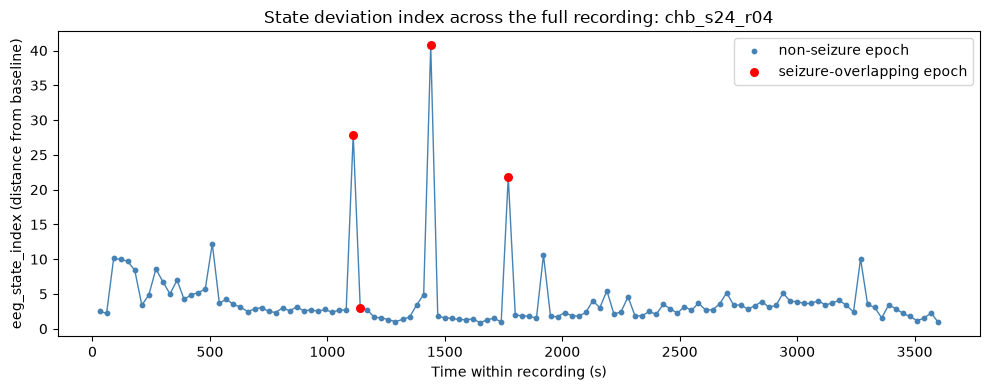

Recording shown: chb_s24_r04 (120 epochs, 4 seizure-overlapping)


In [8]:
print("=" * 60)
print("VISUALIZATION 1: STATE DEVIATION INDEX THROUGH TIME (one example recording)")
print("=" * 60)

example_recording = TRAIN_RECORDINGS[0]
example_rec_df = df[df["recording_id"] == example_recording].sort_values("epoch_idx")

fig1, ax = plt.subplots(figsize=(10, 4))
ax.plot(example_rec_df["t_end_sec"], example_rec_df["eeg_state_index"],
        color="steelblue", linewidth=1, zorder=1)
seizure_pts = example_rec_df[example_rec_df["y_seizure"] == 1]
nonseizure_pts = example_rec_df[example_rec_df["y_seizure"] == 0]
ax.scatter(nonseizure_pts["t_end_sec"], nonseizure_pts["eeg_state_index"],
           s=10, color="steelblue", label="non-seizure epoch", zorder=2)
ax.scatter(seizure_pts["t_end_sec"], seizure_pts["eeg_state_index"],
           s=30, color="red", label="seizure-overlapping epoch", zorder=3)
ax.set_xlabel("Time within recording (s)")
ax.set_ylabel("eeg_state_index (distance from baseline)")
ax.set_title(f"State deviation index across the full recording: {example_recording}")
ax.legend()
plt.tight_layout()
save_fig(fig1, "index_through_time.png")
plt.show()

print(f"Recording shown: {example_recording} ({len(example_rec_df)} epochs, "
      f"{int((example_rec_df['y_seizure']==1).sum())} seizure-overlapping)")

### State Deviation Index Over a Full Recording

The raw `eeg_state_index` is plotted across an entire TRAIN recording, with
seizure-overlapping epochs marked separately. If the index behaves as
intended, seizure epochs should sit visibly above the surrounding
non-seizure baseline level, since seizure activity is expected to look far
from normal by construction; this is a first, purely descriptive check of
whether the distance-based definition preserves any seizure-relevant
structure.


VISUALIZATION 2: STATE DEVIATION INDEX AROUND A SEIZURE ONSET
Auto-selected seizure for this plot: recording=chb_s24_r15, onset=3552s (support=118 epochs)


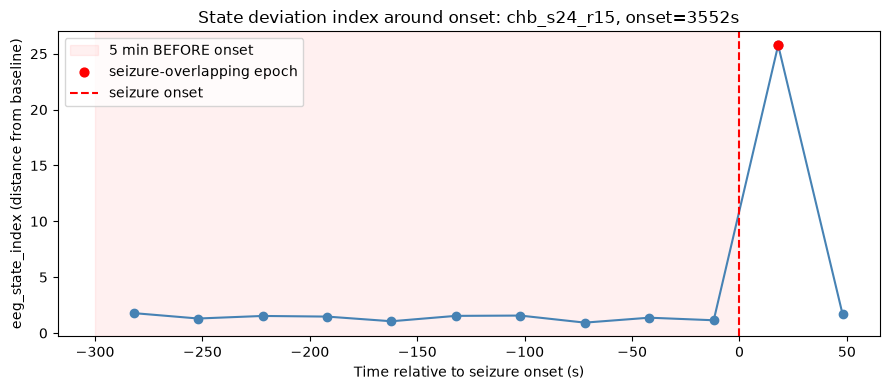


Pre-ictal trend check (this one seizure, descriptive only):
  mean index, -300s to -150s before onset: 1.430 (n=5)
  mean index, -150s to    0s before onset: 1.311 (n=5)
  mean index, seizure-overlapping epochs  : 25.764 (n=1)


In [9]:
print("=" * 60)
print("VISUALIZATION 2: STATE DEVIATION INDEX AROUND A SEIZURE ONSET")
print("=" * 60)

# Descriptive EDA over the FULL dataset (not restricted to test) -- purely
# looking at the raw engineered signal before any model exists, so using
# all recordings here does not leak anything into model training/selection.
support_counts_all = (
    df[df["y_seizure"] == 0]
    .dropna(subset=["next_seizure_start_sec"])
    .groupby(["recording_id", "next_seizure_start_sec"])
    .size()
)
onset_recording, onset_sec = support_counts_all.idxmax()
print(f"Auto-selected seizure for this plot: recording={onset_recording}, "
      f"onset={onset_sec:.0f}s (support={int(support_counts_all.max())} epochs)")

WINDOW_BEFORE = 300
WINDOW_AFTER = 90

around_onset = df[df["recording_id"] == onset_recording].copy()
around_onset["relative_time_sec"] = around_onset["t_end_sec"] - onset_sec
around_onset = around_onset[
    (around_onset["relative_time_sec"] >= -WINDOW_BEFORE)
    & (around_onset["relative_time_sec"] <= WINDOW_AFTER)
].sort_values("relative_time_sec")

fig2, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(-300, 0, color="red", alpha=0.06, zorder=0, label="5 min BEFORE onset")
ax.plot(around_onset["relative_time_sec"], around_onset["eeg_state_index"],
        color="steelblue", marker="o", zorder=1)
seiz = around_onset[around_onset["y_seizure"] == 1]
ax.scatter(seiz["relative_time_sec"], seiz["eeg_state_index"],
           color="red", s=40, zorder=2, label="seizure-overlapping epoch")
ax.axvline(0, color="red", linestyle="--", label="seizure onset")
ax.set_xlabel("Time relative to seizure onset (s)")
ax.set_ylabel("eeg_state_index (distance from baseline)")
ax.set_title(f"State deviation index around onset: {onset_recording}, onset={onset_sec:.0f}s")
ax.legend()
plt.tight_layout()
save_fig(fig2, "index_around_onset.png")
plt.show()

pre_ictal = around_onset[(around_onset["relative_time_sec"] >= -300) & (around_onset["relative_time_sec"] < 0)]
early_pre_ictal = pre_ictal[pre_ictal["relative_time_sec"] < -150]
late_pre_ictal = pre_ictal[pre_ictal["relative_time_sec"] >= -150]
print(f"\nPre-ictal trend check (this one seizure, descriptive only):")
print(f"  mean index, -300s to -150s before onset: {early_pre_ictal['eeg_state_index'].mean():.3f} (n={len(early_pre_ictal)})")
print(f"  mean index, -150s to    0s before onset: {late_pre_ictal['eeg_state_index'].mean():.3f} (n={len(late_pre_ictal)})")
print(f"  mean index, seizure-overlapping epochs  : {seiz['eeg_state_index'].mean():.3f} (n={len(seiz)})")

### State Deviation Index Around a Single Seizure Onset

The `eeg_state_index` is plotted for one seizure event, automatically
selected as the one with the most available lead-up data, from 5 minutes
before onset to 1.5 minutes after; the shaded band marks the 120-second
pre-ictal window this notebook's forecasting task targets. This is the most
direct, model-free view of whether the index drifts or rises within that
window before onset, or remains flat until the seizure epochs themselves
begin; the corresponding early-versus-late pre-ictal means are reported
alongside the plot. The result is reported as observed, and a single
seizure's descriptive trend does not by itself establish a generalizable
precursor pattern in either direction.


VISUALIZATION 3: FORECAST_CLASS DISTRIBUTION
Class distribution (all forecast-eligible epochs):
  class 0 (  0-30s):    38
  class 1 ( 30-60s):    34
  class 2 (60-120s):    62
  class 3 (  >120s):  1837


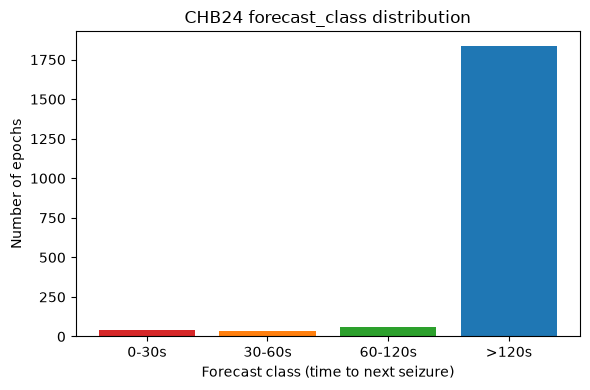

In [10]:
print("=" * 60)
print("VISUALIZATION 3: FORECAST_CLASS DISTRIBUTION")
print("=" * 60)

print("Class distribution (all forecast-eligible epochs):")
for c in CLASS_ORDER:
    print(f"  class {c} ({CLASS_NAMES[c]:>7s}): {int(class_counts[c]):5d}")

fig3, ax = plt.subplots(figsize=(6, 4))
ax.bar([CLASS_NAMES[c] for c in CLASS_ORDER],
       [int(class_counts[c]) for c in CLASS_ORDER],
       color=["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4"])
ax.set_xlabel("Forecast class (time to next seizure)")
ax.set_ylabel("Number of epochs")
ax.set_title("CHB24 forecast_class distribution")
plt.tight_layout()
save_fig(fig3, "class_distribution.png")
plt.show()

### Forecast Class Distribution

The same class imbalance found throughout this project is present here:
seizures are brief relative to an hour of continuous recording, so only a
small fraction of epochs fall within the 0-120s "something imminent" window,
while the majority are correctly labeled `>120s`. This motivates reporting
macro F1 alongside accuracy during evaluation and using class-weighted loss
during training.


In [11]:
print("=" * 60)
print("BUILDING CHRONOLOGICAL INDEX SEQUENCES (SEQUENCE_LENGTH=10 -> 5 min)")
print("=" * 60)

SEQUENCE_LENGTH = 10  # 10 epochs x 30s = 300s = 5 minutes of index history
INDEX_COL = "eeg_state_index"

def build_index_sequences(df_all_epochs, recordings, seq_len):
    '''
    Build (X, y, meta) for one split, using ONLY eeg_state_index as the
    per-timestep feature (not the original 14-D qEEG vector).

    A window is built independently per recording_id (never crosses a
    recording boundary) and its target label is the forecast_class of the
    LAST epoch in the window; windows whose last epoch has
    forecast_class == -1 (seizure-overlapping -> not a valid target) are
    skipped. History epochs may still include seizure-overlapping epochs'
    index values -- only the final/target epoch is restricted.

    Returns:
        X: (n_sequences, seq_len) raw index values per sequence
        y: (n_sequences,) forecast_class of the last epoch
        meta: DataFrame with recording_id, epoch_idx, t_end_sec, forecast_class
    '''
    X_list, y_list, meta_rows = [], [], []

    for recording_id in recordings:
        rec = df_all_epochs[df_all_epochs["recording_id"] == recording_id].sort_values("epoch_idx")
        index_vals = rec[INDEX_COL].to_numpy()
        forecast_vals = rec["forecast_class"].to_numpy()
        epoch_idx_arr = rec["epoch_idx"].to_numpy()
        t_end_arr = rec["t_end_sec"].to_numpy()

        n_epochs = len(rec)
        for i in range(seq_len - 1, n_epochs):
            target_label = int(forecast_vals[i])
            if target_label == -1:
                continue  # target epoch is seizure-overlapping -> not a valid sample
            window = index_vals[i - seq_len + 1 : i + 1]
            if len(window) != seq_len:
                continue
            X_list.append(window)
            y_list.append(target_label)
            meta_rows.append({
                "recording_id": recording_id,
                "epoch_idx": int(epoch_idx_arr[i]),
                "t_end_sec": float(t_end_arr[i]),
                "forecast_class": target_label,
            })

    X = np.stack(X_list, axis=0).astype(np.float32)  # (n_sequences, seq_len)
    y = np.array(y_list, dtype=np.int64)
    meta = pd.DataFrame(meta_rows)
    return X, y, meta

X_train, y_train, meta_train = build_index_sequences(df, TRAIN_RECORDINGS, SEQUENCE_LENGTH)
X_val, y_val, meta_val = build_index_sequences(df, VAL_RECORDINGS, SEQUENCE_LENGTH)
X_test, y_test, meta_test = build_index_sequences(df, TEST_RECORDINGS, SEQUENCE_LENGTH)

print(f"X_train shape: {X_train.shape}  y_train shape: {y_train.shape}")
print(f"X_val   shape: {X_val.shape}  y_val   shape: {y_val.shape}")
print(f"X_test  shape: {X_test.shape}  y_test  shape: {y_test.shape}")

print("\nOne example sequence (first training sequence):")
print(f"  recording_id: {meta_train.iloc[0]['recording_id']}, "
      f"target epoch_idx={meta_train.iloc[0]['epoch_idx']} "
      f"(t_end_sec={meta_train.iloc[0]['t_end_sec']:.0f}s)")
print(f"  forecast_class of target epoch: {y_train[0]} ({CLASS_NAMES[int(y_train[0])]})")
print(f"  X_train[0] (10 consecutive index values, oldest -> newest):")
print(f"    {X_train[0].round(3)}")

BUILDING CHRONOLOGICAL INDEX SEQUENCES (SEQUENCE_LENGTH=10 -> 5 min)
X_train shape: (1186, 10)  y_train shape: (1186,)
X_val   shape: (318, 10)  y_val   shape: (318,)
X_test  shape: (318, 10)  y_test  shape: (318,)

One example sequence (first training sequence):
  recording_id: chb_s24_r04, target epoch_idx=9 (t_end_sec=300s)
  forecast_class of target epoch: 3 (>120s)
  X_train[0] (10 consecutive index values, oldest -> newest):
    [ 2.535  2.205 10.102  9.984  9.688  8.406  3.404  4.865  8.606  6.729]


### Chronological Sequence Construction

Each training example is a length-10 sequence of `eeg_state_index` values --
10 consecutive 30-second epochs from one recording -- with shape `(N, 10)`.
`y_train[i]` is the `forecast_class` of the last (most recent) index value
in `X_train[i]`. Sequence windows never cross a recording boundary; history
epochs may include seizure-overlapping index values even when the window's
target epoch is not itself seizure-overlapping, consistent with the
sequence-construction convention used elsewhere in this project.


In [12]:
print("=" * 60)
print("PYTORCH TENSORS, DATASETS, DATALOADERS")
print("=" * 60)

import torch
from torch.utils.data import TensorDataset, DataLoader

print(f"torch version: {torch.__version__}  (CUDA available: {torch.cuda.is_available()})")
torch.manual_seed(RANDOM_SEED)

# Add an explicit "channel" dimension of size 1: (N, 10) -> (N, 10, 1).
X_train_t = torch.from_numpy(X_train).unsqueeze(-1)
y_train_t = torch.from_numpy(y_train)
X_val_t = torch.from_numpy(X_val).unsqueeze(-1)
y_val_t = torch.from_numpy(y_val)
X_test_t = torch.from_numpy(X_test).unsqueeze(-1)
y_test_t = torch.from_numpy(y_test)

BATCH_SIZE = 32

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

xb_example, yb_example = next(iter(train_loader))
print(f"\nOne training batch: xb shape={tuple(xb_example.shape)}, yb shape={tuple(yb_example.shape)}")
print(f"  ({xb_example.shape[0]} sequences, {xb_example.shape[1]} timesteps, {xb_example.shape[2]} channel)")
print(f"\nDataset sizes -- train: {len(train_loader.dataset)}, val: {len(val_loader.dataset)}, test: {len(test_loader.dataset)}")

PYTORCH TENSORS, DATASETS, DATALOADERS


torch version: 2.13.0+cpu  (CUDA available: False)

One training batch: xb shape=(32, 10, 1), yb shape=(32,)
  (32 sequences, 10 timesteps, 1 channel)

Dataset sizes -- train: 1186, val: 318, test: 318


### PyTorch Data Pipeline

The index sequences are wrapped into `TensorDataset`/`DataLoader` objects
with `BATCH_SIZE = 32`; training batches are reshuffled each epoch, while
validation and test are evaluated in a fixed order. Tensors enter the model
with shape `(batch, 10, 1)` -- `(batch, time, channel)` -- which the model
transposes internally to `(batch, channel, time)` for `Conv1d`.


In [13]:
print("=" * 60)
print("TCN ARCHITECTURE (single-channel EEG-state-index input, unchanged)")
print("=" * 60)

import torch.nn as nn
import torch.nn.functional as F


class CausalConv1d(nn.Module):
    '''
    A Conv1d that only looks BACKWARD in time. Padding only the LEFT side by
    (kernel_size - 1) * dilation keeps the output length equal to the input
    length while guaranteeing output[t] depends only on input[<= t] -- never
    on future timesteps.
    '''

    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        self.left_pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size, padding=0, dilation=dilation)

    def forward(self, x):
        x = F.pad(x, (self.left_pad, 0))
        return self.conv(x)


class IndexTCN(nn.Module):
    '''
    A small 3-block causal, dilated TCN whose input is the 1-D EEG state
    index trajectory (1 channel).

    Input : (batch, seq_len, 1)  -- as produced by the DataLoader
    Output: (batch, n_classes)   -- raw logits
    '''

    def __init__(self, n_classes, hidden=16, kernel_size=3):
        super().__init__()
        self.block1 = CausalConv1d(1, hidden, kernel_size, dilation=1)
        self.block2 = CausalConv1d(hidden, hidden, kernel_size, dilation=2)
        self.block3 = CausalConv1d(hidden, hidden, kernel_size, dilation=4)
        self.relu = nn.ReLU()
        self.classifier = nn.Linear(hidden, n_classes)

    def forward(self, x):
        x = x.transpose(1, 2)  # (batch, time, 1 channel) -> (batch, 1 channel, time)
        h = self.relu(self.block1(x))
        h = self.relu(self.block2(h))
        h = self.relu(self.block3(h))
        last_timestep = h[:, :, -1]        # representation of "now", after seeing the full window
        logits = self.classifier(last_timestep)
        return logits


N_CLASSES = 4
model = IndexTCN(n_classes=N_CLASSES, hidden=16, kernel_size=3)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nTrainable parameters: {n_params:,}")

with torch.no_grad():
    probe = torch.randn(1, SEQUENCE_LENGTH, 1)
    out_original = model(probe)
    probe_perturbed = probe.clone()
    probe_perturbed[:, :5, :] = 0.0  # zero the OLDEST half (the past)
    out_perturbed = model(probe_perturbed)
    changed_by_past = not torch.allclose(out_original, out_perturbed, atol=1e-6)
print(f"\nCausality sanity check: changing PAST timesteps changes the output "
      f"= {changed_by_past} (expected True)")

TCN ARCHITECTURE (single-channel EEG-state-index input, unchanged)
IndexTCN(
  (block1): CausalConv1d(
    (conv): Conv1d(1, 16, kernel_size=(3,), stride=(1,))
  )
  (block2): CausalConv1d(
    (conv): Conv1d(16, 16, kernel_size=(3,), stride=(1,), dilation=(2,))
  )
  (block3): CausalConv1d(
    (conv): Conv1d(16, 16, kernel_size=(3,), stride=(1,), dilation=(4,))
  )
  (relu): ReLU()
  (classifier): Linear(in_features=16, out_features=4, bias=True)
)

Trainable parameters: 1,700



Causality sanity check: changing PAST timesteps changes the output = True (expected True)


### TCN Architecture (Single-Channel Input)

The model is the same causal, dilated TCN architecture used throughout this
project, with `in_channels=1` since the input is a single scalar trajectory
(the state deviation index) rather than the original 14-dimensional qEEG
vector:

```text
Input: 10 consecutive eeg_state_index values (batch, 1, 10) after transpose
        |
Causal Conv1d, dilation=1   (relates each point to its immediate neighbors)
        |
Causal Conv1d, dilation=2   (relates points further apart)
        |
Causal Conv1d, dilation=4   (spans the full 10-step, 5-minute window)
        |
representation at the last timestep
        |
Linear layer -> 4 logits
```

Because the input carries one number per timestep, the convolutional
filters can only combine shape features of the index trajectory itself --
whether the distance from baseline is rising, falling, accelerating, or
oscillating over the preceding 5 minutes -- at different time-scales set by
each layer's dilation. Since the index already encodes how far an epoch is
from normal, the network's task is to detect whether the trend of that
deviation, not merely its instantaneous level, is predictive of an imminent
seizure.


In [14]:
print("=" * 60)
print("CLASS WEIGHTS (computed from TRAIN labels only)")
print("=" * 60)

from sklearn.utils.class_weight import compute_class_weight

class_labels = np.array(CLASS_ORDER)
class_weights_np = compute_class_weight(class_weight="balanced", classes=class_labels, y=y_train)
class_weights_tensor = torch.tensor(class_weights_np, dtype=torch.float32)

train_counts = pd.Series(y_train).value_counts().sort_index().reindex(class_labels, fill_value=0)
print("Train label counts:")
print(train_counts)
print("\nComputed class weights (higher weight = rarer class):")
for c, w in zip(class_labels, class_weights_np):
    print(f"  class {c} ({CLASS_NAMES[c]:>7s}): weight={w:.3f}")

CLASS WEIGHTS (computed from TRAIN labels only)
Train label counts:
0      18
1      17
2      30
3    1121
Name: count, dtype: int64

Computed class weights (higher weight = rarer class):
  class 0 (  0-30s): weight=16.472
  class 1 ( 30-60s): weight=17.441
  class 2 (60-120s): weight=9.883
  class 3 (  >120s): weight=0.264


### Class-Weighted Loss

One loss weight per class is computed from the TRAIN labels only, using
`compute_class_weight("balanced", ...)`, setting each class's weight
inversely proportional to its TRAIN frequency so that
`CrossEntropyLoss(weight=...)` penalizes rare-class mistakes more than
common-class mistakes.


TRAINING THE STATE-DEVIATION-INDEX TCN


Epoch 01 | train_loss=1.3920 | val_loss=1.3498 | val_macro_f1=0.2393


Epoch 02 | train_loss=1.3453 | val_loss=1.4230 | val_macro_f1=0.2376


Epoch 03 | train_loss=1.3445 | val_loss=1.5207 | val_macro_f1=0.2372


Epoch 04 | train_loss=1.3327 | val_loss=1.5603 | val_macro_f1=0.2346


Epoch 05 | train_loss=1.3281 | val_loss=1.6526 | val_macro_f1=0.2314


... (7 outputs left out)

Epoch 13 | train_loss=1.2475 | val_loss=2.2791 | val_macro_f1=0.2446


Epoch 14 | train_loss=1.2581 | val_loss=2.2613 | val_macro_f1=0.2436


Epoch 15 | train_loss=1.2385 | val_loss=2.3640 | val_macro_f1=0.2446


Epoch 16 | train_loss=1.1968 | val_loss=2.6865 | val_macro_f1=0.2337

Early stopping at epoch 16: no val_macro_f1 improvement for 8 epochs.

Loaded best model weights (val_macro_f1=0.2638).


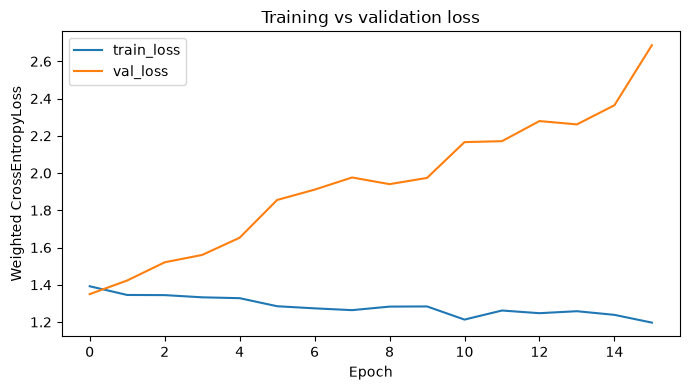

In [15]:
print("=" * 60)
print("TRAINING THE STATE-DEVIATION-INDEX TCN")
print("=" * 60)

import copy
from sklearn.metrics import f1_score

MAX_EPOCHS = 40
LEARNING_RATE = 1e-3
PATIENCE = 8

torch.manual_seed(RANDOM_SEED)
model = IndexTCN(n_classes=N_CLASSES, hidden=16, kernel_size=3)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}
best_val_f1 = -1.0
best_state = None
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_losses = []
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    model.eval()
    val_losses, all_preds, all_targets = [], [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            logits = model(xb)
            val_losses.append(criterion(logits, yb).item())
            all_preds.append(logits.argmax(dim=1))
            all_targets.append(yb)
    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()
    val_macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(val_macro_f1)

    print(f"Epoch {epoch:02d} | train_loss={train_loss:.4f} | "
          f"val_loss={val_loss:.4f} | val_macro_f1={val_macro_f1:.4f}")

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch}: no val_macro_f1 "
                  f"improvement for {PATIENCE} epochs.")
            break

model.load_state_dict(best_state)
print(f"\nLoaded best model weights (val_macro_f1={best_val_f1:.4f}).")

fig4, ax = plt.subplots(figsize=(7, 4))
ax.plot(history["train_loss"], label="train_loss")
ax.plot(history["val_loss"], label="val_loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted CrossEntropyLoss")
ax.set_title("Training vs validation loss")
ax.legend()
plt.tight_layout()
save_fig(fig4, "training_curve.png")
plt.show()

### Model Training

The TCN is trained with the Adam optimizer (`LEARNING_RATE = 1e-3`) and the
class-weighted cross-entropy loss, for up to `MAX_EPOCHS = 40` epochs, with
early stopping once `PATIENCE = 8` epochs pass without improvement in
validation macro F1; the weights from the best-scoring epoch (`best_state`)
are restored rather than those from the final epoch trained. Both training
and validation loss trending down together indicates healthy learning,
while a widening gap -- training loss continuing to fall while validation
loss rises or plateaus -- indicates overfitting to TRAIN-specific patterns.


HELD-OUT TEST EVALUATION (evaluated ONCE)
Test label support per class:
  class 0 (  0-30s): 10 examples
  class 1 ( 30-60s): 8 examples
  class 2 (60-120s): 16 examples
  class 3 (  >120s): 284 examples

Overall accuracy: 0.7893
Macro F1        : 0.2206

Confusion matrix (rows=true, cols=predicted):
              pred_0-30s  pred_30-60s  pred_60-120s  pred_>120s
true_0-30s             0            0             0          10
true_30-60s            0            0             0           8
true_60-120s           0            0             0          16
true_>120s             0           10            23         251

Classification report:
              precision    recall  f1-score   support

       0-30s       0.00      0.00      0.00        10
      30-60s       0.00      0.00      0.00         8
     60-120s       0.00      0.00      0.00        16
       >120s       0.88      0.88      0.88       284

    accuracy                           0.79       318
   macro avg       0.22     

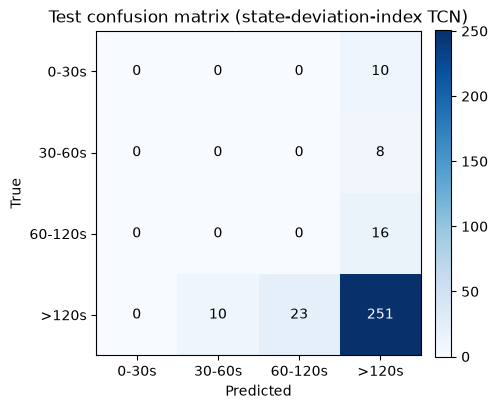

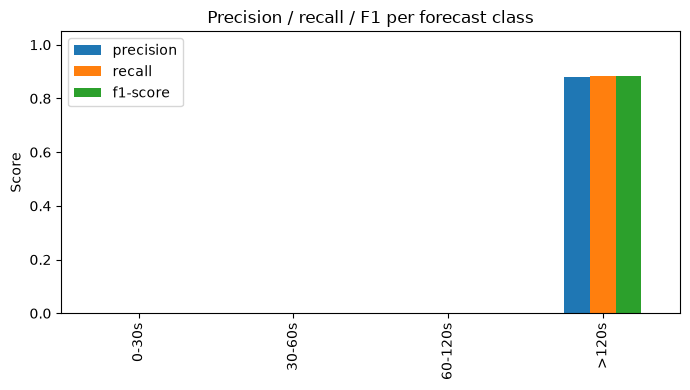

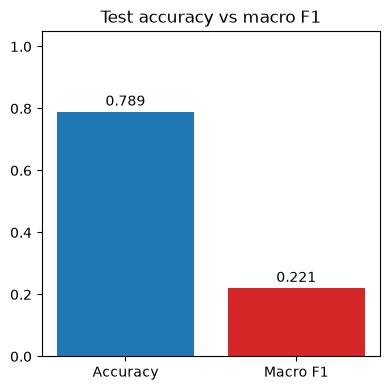

In [16]:
print("=" * 60)
print("HELD-OUT TEST EVALUATION (evaluated ONCE)")
print("=" * 60)

from sklearn.metrics import confusion_matrix, classification_report

CLASS_LABELS_DISPLAY = [CLASS_NAMES[c] for c in CLASS_ORDER]

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_probs = torch.softmax(test_logits, dim=1).numpy()
    test_preds = test_logits.argmax(dim=1).numpy()

test_accuracy = float((test_preds == y_test).mean())
test_macro_f1 = f1_score(y_test, test_preds, average="macro", zero_division=0)

cm = confusion_matrix(y_test, test_preds, labels=CLASS_ORDER)
report_dict = classification_report(
    y_test, test_preds, labels=CLASS_ORDER, target_names=CLASS_LABELS_DISPLAY,
    output_dict=True, zero_division=0,
)
report_text = classification_report(
    y_test, test_preds, labels=CLASS_ORDER, target_names=CLASS_LABELS_DISPLAY,
    zero_division=0,
)

test_support = pd.Series(y_test).value_counts().sort_index().reindex(CLASS_ORDER, fill_value=0)
print("Test label support per class:")
for c in CLASS_ORDER:
    flag = "  <-- very few test examples, interpret with caution" if test_support[c] < 5 else ""
    print(f"  class {c} ({CLASS_NAMES[c]:>7s}): {int(test_support[c])} examples{flag}")

print(f"\nOverall accuracy: {test_accuracy:.4f}")
print(f"Macro F1        : {test_macro_f1:.4f}")
print("\nConfusion matrix (rows=true, cols=predicted):")
print(pd.DataFrame(cm, index=[f"true_{l}" for l in CLASS_LABELS_DISPLAY],
                    columns=[f"pred_{l}" for l in CLASS_LABELS_DISPLAY]))
print("\nClassification report:")
print(report_text)

# Confusion matrix figure
fig_cm, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASS_LABELS_DISPLAY))); ax.set_yticks(range(len(CLASS_LABELS_DISPLAY)))
ax.set_xticklabels(CLASS_LABELS_DISPLAY); ax.set_yticklabels(CLASS_LABELS_DISPLAY)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Test confusion matrix (state-deviation-index TCN)")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
save_fig(fig_cm, "confusion_matrix.png")
plt.show()

# Per-class precision/recall/F1 figure
metrics_per_class = pd.DataFrame({
    "precision": [report_dict[l]["precision"] for l in CLASS_LABELS_DISPLAY],
    "recall": [report_dict[l]["recall"] for l in CLASS_LABELS_DISPLAY],
    "f1-score": [report_dict[l]["f1-score"] for l in CLASS_LABELS_DISPLAY],
}, index=CLASS_LABELS_DISPLAY)

fig_pc, ax = plt.subplots(figsize=(7, 4))
metrics_per_class.plot(kind="bar", ax=ax)
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Precision / recall / F1 per forecast class")
ax.legend(loc="upper left")
plt.tight_layout()
save_fig(fig_pc, "per_class_precision_recall_f1.png")
plt.show()

# Accuracy vs macro-F1 summary figure
fig_summary, ax = plt.subplots(figsize=(4, 4))
ax.bar(["Accuracy", "Macro F1"], [test_accuracy, test_macro_f1], color=["#1f77b4", "#d62728"])
ax.set_ylim(0, 1.05)
ax.set_title("Test accuracy vs macro F1")
for i, v in enumerate([test_accuracy, test_macro_f1]):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center")
plt.tight_layout()
save_fig(fig_summary, "accuracy_vs_macro_f1.png")
plt.show()

### Held-Out Test Evaluation

The best (early-stopped) model is evaluated exactly once on the TEST
recordings, which were not used during training or model selection.

Macro F1 is used as the primary metric because it averages the F1 score of
each of the 4 classes unweighted, so the rare 0-30s/30-60s/60-120s classes
count as much as the dominant `>120s` class; plain accuracy is dominated by
whichever class has the most examples, and a large gap between accuracy and
macro F1 signals a model relying on the dominant class rather than
discriminating the rare, clinically relevant ones. In the confusion matrix,
rows are the true class and columns the predicted class; off-diagonal mass
in the imminent-class rows corresponds to missed imminent seizures.
Precision and recall are reported per class, since a single averaged number
can mask a model that performs well on the common class but poorly on the
rare ones; classes with very few test examples give correspondingly noisy
per-class estimates.


In [17]:
print("=" * 60)
print("CUMULATIVE TRANSITION-RISK PROBABILITIES")
print("=" * 60)

p0, p1, p2, p3 = test_probs[:, 0], test_probs[:, 1], test_probs[:, 2], test_probs[:, 3]
P_30 = p0
P_60 = p0 + p1
P_120 = p0 + p1 + p2

cumulative_ok = bool(np.all(P_30 <= P_60 + 1e-6) and np.all(P_60 <= P_120 + 1e-6))
print(f"Cumulative ordering P_30 <= P_60 <= P_120 holds for all test sequences: {cumulative_ok}")

print("\nExample (first 5 test sequences):")
print(pd.DataFrame({
    "recording_id": meta_test["recording_id"].iloc[:5].values,
    "t_end_sec": meta_test["t_end_sec"].iloc[:5].values,
    "true_class": y_test[:5],
    "P_30": P_30[:5].round(3), "P_60": P_60[:5].round(3), "P_120": P_120[:5].round(3),
}).to_string(index=False))

CUMULATIVE TRANSITION-RISK PROBABILITIES
Cumulative ordering P_30 <= P_60 <= P_120 holds for all test sequences: True

Example (first 5 test sequences):
recording_id  t_end_sec  true_class  P_30  P_60  P_120
 chb_s24_r01      300.0           3 0.193 0.386  0.638
 chb_s24_r01      330.0           3 0.192 0.362  0.619
 chb_s24_r01      360.0           2 0.188 0.371  0.637
 chb_s24_r01      390.0           2 0.191 0.382  0.639
 chb_s24_r01      420.0           1 0.206 0.396  0.666


### Cumulative Transition-Risk Probabilities

The model's 4 output probabilities describe mutually exclusive time
intervals; summing them yields probabilities for the overlapping question of
whether a seizure will occur within a given number of seconds:

```text
P_30  = p0                = P(seizure within 30s)
P_60  = p0 + p1            = P(seizure within 60s)
P_120 = p0 + p1 + p2       = P(seizure within 120s)
```

Because these are cumulative sums of the same softmax distribution, `P_30 <=
P_60 <= P_120` holds by construction for every prediction; this is verified
directly against the test set.


TRANSITION-RISK CURVE AROUND A HELD-OUT TEST SEIZURE


Auto-selected TEST seizure: recording=chb_s24_r21, onset=2804s (support=84 lead-up sequences)
Sequences shown: 10, spanning -284s to -14s relative to onset (0 = onset)


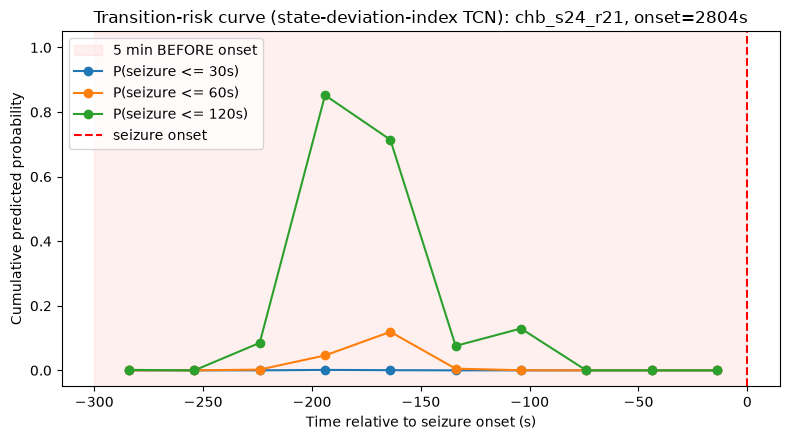

In [18]:
print("=" * 60)
print("TRANSITION-RISK CURVE AROUND A HELD-OUT TEST SEIZURE")
print("=" * 60)

meta_test_scored = meta_test.copy()
meta_test_scored["P_30"] = P_30
meta_test_scored["P_60"] = P_60
meta_test_scored["P_120"] = P_120

onset_lookup = df.set_index(["recording_id", "epoch_idx"])["next_seizure_start_sec"]
meta_test_scored["next_seizure_start_sec"] = [
    onset_lookup.loc[(r, e)] for r, e in zip(meta_test_scored["recording_id"], meta_test_scored["epoch_idx"])
]
support_counts_test = (
    meta_test_scored.dropna(subset=["next_seizure_start_sec"])
    .groupby(["recording_id", "next_seizure_start_sec"]).size()
)
chosen_recording, chosen_onset = support_counts_test.idxmax()
print(f"Auto-selected TEST seizure: recording={chosen_recording}, onset={chosen_onset:.0f}s "
      f"(support={int(support_counts_test.max())} lead-up sequences)")

WINDOW_BEFORE_ONSET_SEC = 300
lead_up = meta_test_scored[
    (meta_test_scored["recording_id"] == chosen_recording)
    & (meta_test_scored["next_seizure_start_sec"] == chosen_onset)
].copy()
lead_up["relative_time_sec"] = lead_up["t_end_sec"] - chosen_onset
lead_up = lead_up[lead_up["relative_time_sec"] >= -WINDOW_BEFORE_ONSET_SEC].sort_values("relative_time_sec")
print(f"Sequences shown: {len(lead_up)}, spanning "
      f"{lead_up['relative_time_sec'].min():.0f}s to {lead_up['relative_time_sec'].max():.0f}s "
      f"relative to onset (0 = onset)")

fig_transition, ax = plt.subplots(figsize=(8, 4.5))
ax.axvspan(-300, 0, color="red", alpha=0.06, zorder=0, label="5 min BEFORE onset")
ax.plot(lead_up["relative_time_sec"], lead_up["P_30"], marker="o", label="P(seizure <= 30s)")
ax.plot(lead_up["relative_time_sec"], lead_up["P_60"], marker="o", label="P(seizure <= 60s)")
ax.plot(lead_up["relative_time_sec"], lead_up["P_120"], marker="o", label="P(seizure <= 120s)")
ax.axvline(0, color="red", linestyle="--", label="seizure onset")
ax.set_xlabel("Time relative to seizure onset (s)")
ax.set_ylabel("Cumulative predicted probability")
ax.set_ylim(-0.05, 1.05)
ax.set_title(f"Transition-risk curve (state-deviation-index TCN): {chosen_recording}, onset={chosen_onset:.0f}s")
ax.legend()
plt.tight_layout()
save_fig(fig_transition, "transition_risk_curve.png")
plt.show()

### Transition-Risk Curve for a Held-Out Seizure

For one real, held-out TEST seizure, automatically selected for having the
most supporting lead-up sequences, `P_30`, `P_60`, `P_120` are plotted
across the minutes leading up to its actual onset, with the same 120-second
pre-ictal band shown. Each point represents what the model would predict
using only the state-deviation-index trajectory available up through that
moment, mirroring real-time use; a rise in the curves within the shaded
band, before onset, would indicate the model is picking up a precursor
pattern in how the deviation from baseline is trending, while a flat or
noisy curve up to onset is reported as such.


In [19]:
print("=" * 60)
print("SAVING ARTIFACTS (CHB24 + CHB12 combined run -- overwrites the CHB24-only run)")
print("=" * 60)

import joblib

torch.save(model.state_dict(), model_out_dir / "tcn_state_deviation_model.pt")
joblib.dump(scaler, model_out_dir / "feature_scaler.joblib")
joblib.dump(pca, model_out_dir / "index_pca.joblib")

with open(model_out_dir / "split_recordings.json", "w") as f:
    json.dump({"train": TRAIN_RECORDINGS, "validation": VAL_RECORDINGS, "test": TEST_RECORDINGS}, f, indent=2)

with open(model_out_dir / "training_history.json", "w") as f:
    json.dump(history, f, indent=2)

test_metrics = {
    "accuracy": test_accuracy,
    "macro_f1": test_macro_f1,
    "confusion_matrix": cm.tolist(),
    "classification_report": report_dict,
    "class_order": CLASS_ORDER,
    "class_names": CLASS_NAMES,
    "test_support_per_class": {int(c): int(test_support[c]) for c in CLASS_ORDER},
}
with open(model_out_dir / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

state_index_config = {
    "method": "PCA-whitened Euclidean distance from a TRAIN stable-baseline centroid "
              "(Mahalanobis distance under a rank-truncated/regularized baseline covariance)",
    "baseline_definition": "TRAIN-recording epochs with y_seizure == 0 and forecast_class == 3 (>120s to next seizure)",
    "datasets_used": ["chb24", "chb12"],
    "n_baseline_epochs": n_baseline,
    "n_train_epochs_total": n_train_total,
    "baseline_covariance_numerical_rank": rank_cov,
    "baseline_covariance_condition_number": condition_number,
    "variance_retain_threshold": VARIANCE_RETAIN,
    "n_components_kept": n_components_kept,
    "cumulative_variance_kept": float(cum_var[n_components_kept - 1]),
    "pca_explained_variance_ratio_all_components": pca.explained_variance_ratio_.tolist(),
    "pca_eigenvalues_all_components": pca.explained_variance_.tolist(),
    "mean_index_baseline_epochs": float(mean_index_baseline),
    "mean_index_train_near_seizure_epochs": float(mean_index_near_seizure),
    "mean_index_seizure_overlapping_epochs": float(mean_index_seizure),
}
with open(model_out_dir / "state_index_config.json", "w") as f:
    json.dump(state_index_config, f, indent=2)

config = {
    "datasets_used": ["chb24", "chb12"],
    "sequence_length": SEQUENCE_LENGTH,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "patience": PATIENCE,
    "random_seed": RANDOM_SEED,
    "index_method": "PCA-whitened Mahalanobis-equivalent distance from TRAIN stable baseline "
                     "(see state_index_config.json for full detail)",
    "n_train_sequences": int(len(y_train)),
    "n_val_sequences": int(len(y_val)),
    "n_test_sequences": int(len(y_test)),
    "best_val_macro_f1": float(best_val_f1),
}
with open(model_out_dir / "run_config.json", "w") as f:
    json.dump(config, f, indent=2)

print(f"Saved to {model_out_dir}:")
for p in sorted(model_out_dir.iterdir()):
    print(f"  {p.name}")

SAVING ARTIFACTS (CHB24 + CHB12 combined run -- overwrites the CHB24-only run)
Saved to /home/evgenija/projects/EEG_timeseries_project/outputs/modeling/tcn_state_deviation_forecasting:
  accuracy_vs_macro_f1.png
  class_distribution.png
  confusion_matrix.png
  feature_scaler.joblib
  index_around_onset.png
  index_pca.joblib
  index_through_time.png
  per_class_precision_recall_f1.png
  run_config.json
  split_recordings.json
  state_index_config.json
  tcn_state_deviation_model.pt
  test_metrics.json
  training_curve.png
  training_history.json
  transition_risk_curve.png


### Artifact Export

All results needed to reproduce or reuse this experiment are saved under
`outputs/modeling/tcn_state_deviation_forecasting/`: the trained model
weights (`tcn_state_deviation_model.pt`); the fitted baseline
standardization and whitening PCA (`feature_scaler.joblib`,
`index_pca.joblib`), sufficient to compute `eeg_state_index` identically for
any new epoch at inference time; the baseline definition, covariance
diagnostics, and retained-component count (`state_index_config.json`); the
recording split, training history, test metrics, and run configuration
(`split_recordings.json`, `training_history.json`, `test_metrics.json`,
`run_config.json`); and eight corresponding PNG figures.


In [20]:
print("=" * 60)
print("FINAL RUN SUMMARY (CHB24 + CHB12 combined)")
print("=" * 60)
print(f'''
Datasets                   : CHB24 + CHB12
Index method              : PCA-whitened distance from TRAIN stable baseline (Mahalanobis-equivalent)
Baseline epochs            : {n_baseline} / {n_train_total} TRAIN epochs (non-seizure, >120s to next seizure)
Components kept            : {n_components_kept} / {len(FEATURE_COLS)} ({cum_var[n_components_kept-1]*100:.2f}% baseline variance)
Baseline covariance rank   : {rank_cov} / {len(FEATURE_COLS)} (condition number {condition_number:.2e})
Recordings                 : {df['recording_id'].nunique()} (TRAIN={len(TRAIN_RECORDINGS)}, VAL={len(VAL_RECORDINGS)}, TEST={len(TEST_RECORDINGS)})
Sequence length             : {SEQUENCE_LENGTH} epochs ({SEQUENCE_LENGTH*30}s = {SEQUENCE_LENGTH*30/60:.0f} min)
Sequences (train/val/test)  : {len(y_train)} / {len(y_val)} / {len(y_test)}
Class counts (eligible epochs): ''' + ", ".join(f"{CLASS_NAMES[c]}={int(class_counts[c])}" for c in CLASS_ORDER) + f'''
Best validation macro F1   : {best_val_f1:.4f}
Test accuracy               : {test_accuracy:.4f}
Test macro F1               : {test_macro_f1:.4f}
Mean index -- baseline epochs           : {mean_index_baseline:.3f}
Mean index -- TRAIN near-seizure epochs : {mean_index_near_seizure:.3f}
Mean index -- seizure-overlapping epochs: {mean_index_seizure:.3f}
''')

FINAL RUN SUMMARY (CHB24 + CHB12 combined)

Datasets                   : CHB24 + CHB12
Index method              : PCA-whitened distance from TRAIN stable baseline (Mahalanobis-equivalent)
Baseline epochs            : 1213 / 1320 TRAIN epochs (non-seizure, >120s to next seizure)
Components kept            : 8 / 14 (99.15% baseline variance)
Baseline covariance rank   : 13 / 14 (condition number 9.15e+09)
Recordings                 : 17 (TRAIN=11, VAL=3, TEST=3)
Sequence length             : 10 epochs (300s = 5 min)
Sequences (train/val/test)  : 1186 / 318 / 318
Class counts (eligible epochs): 0-30s=38, 30-60s=34, 60-120s=62, >120s=1837
Best validation macro F1   : 0.2638
Test accuracy               : 0.7893
Test macro F1               : 0.2206
Mean index -- baseline epochs           : 2.357
Mean index -- TRAIN near-seizure epochs : 2.400
Mean index -- seizure-overlapping epochs: 11.350



## Final Results

This is the final, combined-data experiment: **CHB24 + the processed CHB12
subset**, evaluated on whole held-out recordings.

**Data**

| | value |
|---|---|
| Total seizure events (CHB24 16 + CHB12 19) | **35** |
| Recordings | 17 (12 CHB24 + 5 CHB12), split TRAIN=11 / VAL=3 / TEST=3 |
| Class counts (all forecast-eligible epochs) | 0-30s = **38**, 30-60s = **34**, 60-120s = **62**, >120s = **1837** |

**Sequence tensors** (10 epochs = 5 minutes of index history each)

| split | shape |
|---|---|
| Train | `(1186, 10, 1)` |
| Validation | `(318, 10, 1)` |
| Test | `(318, 10, 1)` |

**Model performance**

| metric | value |
|---|---|
| Best validation macro-F1 (model-selection criterion) | **0.2638** |
| Test accuracy | **0.7893** |
| Test macro-F1 | **0.2206** |

**Per-class test performance**

| class | precision | recall | F1 | support |
|---|---|---|---|---|
| 0-30s | 0.00 | 0.00 | 0.00 | 10 |
| 30-60s | 0.00 | 0.00 | 0.00 | 8 |
| 60-120s | 0.00 | 0.00 | 0.00 | 16 |
| >120s | 0.881 | 0.884 | **0.882** | 284 |

**The three imminent-seizure classes (0-30s, 30-60s, 60-120s) have 0.00
recall and 0.00 F1 on held-out test data.** All test-set performance comes
from the dominant, non-urgent `>120s` class.

---

## Interpretation and Conclusions

- **The full forecasting pipeline was implemented successfully**, end to
  end: raw CHB-MIT EEG -> 30-second epochs -> 14 qEEG features -> a single
  State Deviation Index per epoch -> a 5-minute (10-epoch) index trajectory
  -> a causal dilated TCN -> a 4-class time-to-next-seizure prediction ->
  a cumulative transition-risk curve. Every stage runs, validates its own
  output, and is checkpointed/reproducible.
- **The model was explicitly trained to predict time until the next
  seizure** (0-30s / 30-60s / 60-120s / >120s), not merely to detect a
  seizure already in progress -- this is a genuine forecasting task, evaluated
  on whole held-out recordings from two subjects.
- **The State Deviation Index strongly reacts *during* seizure activity**:
  its mean value jumps from ~2.4 in normal/near-seizure epochs to ~11-25 in
  seizure-overlapping epochs (recording-dependent) -- confirming the index
  is physiologically meaningful and sensitive to genuinely abnormal EEG.
- **However, it did not show a consistent pre-ictal rise in the 120-second
  window before onset.** The index-around-onset plot stays flat for the
  full 5 minutes leading up to a seizure and only spikes once the seizure
  epoch itself begins; the transition-risk curve is noisy and
  non-monotonic rather than rising toward onset.
- **The TCN therefore failed to correctly identify the three
  imminent-seizure classes on held-out test data** -- 0.00 recall and 0.00
  F1 for 0-30s, 30-60s, and 60-120s, despite combining two subjects and 35
  total seizure events.
- **Accuracy alone is misleading here because of class imbalance**: 0.789
  test accuracy sounds reasonable, but it is achieved almost entirely by
  the dominant `>120s` class (89% of test epochs); macro-F1 (0.221), which
  weighs all four classes equally, is the honest summary number, and it is
  barely above what a model with zero imminent-class skill would produce.
- **The forecasting hypothesis was NOT demonstrated by this limited
  proof-of-concept.** The pipeline works mechanically; the underlying
  scientific question ("does this qEEG-derived index carry a learnable
  pre-seizure precursor signal?") is answered honestly as **no, not with
  this data and representation**.
- **This does not prove seizure forecasting is impossible.** It shows only
  that *this* 14-feature qEEG representation, collapsed to *this*
  single-scalar distance index, over a *120-second* pre-ictal window, on
  *these* 2 subjects (35 seizure events, 2040 epochs total), did not
  contain enough learnable precursor information for this TCN to exploit.
  A different feature set, a longer pre-ictal window, more subjects, or a
  richer (non-scalar) representation could plausibly behave differently --
  none of that is tested here.
